In [1]:
# CELL 1 — Mount Google Drive
# Purpose: give Colab access to your drive so we can load data + save models.
from google.colab import drive
drive.mount('/content/drive')
print("✅ Google Drive mounted!")


Mounted at /content/drive
✅ Google Drive mounted!


In [2]:
# CELL 2 — Set paths and extract dataset if zipped
# Purpose: confirm the ZIP exists, extract it, and set BASE variable.

import zipfile
import os

# EDIT THIS if you put the zip elsewhere
ZIP_PATH = "/content/drive/MyDrive/mel_3ch.zip"
BASE = "/content/processed/mel_3ch"  # expected folder after extraction

if os.path.exists(ZIP_PATH):
    print("✅ Found zip:", ZIP_PATH)
    # Extract only if BASE doesn't already exist to save time
    if not os.path.exists(BASE):
        print("📦 Extracting zip to /content (may take a minute)...")
        with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
            zip_ref.extractall('/content')
        print("✅ Extraction complete.")
    else:
        print("⚠️ Base directory already exists:", BASE)
else:
    print("❌ ZIP not found at:", ZIP_PATH)
    print("Please upload mel_3ch.zip to the path above or change ZIP_PATH.")
    # List drive root to help find files
    !ls -lh /content/drive/MyDrive/

# Final sanity
if not os.path.exists(BASE):
    raise FileNotFoundError(f"Expected dataset folder not found at {BASE}. Update ZIP_PATH or BASE.")
else:
    print("Using dataset base:", BASE)


✅ Found zip: /content/drive/MyDrive/mel_3ch.zip
📦 Extracting zip to /content (may take a minute)...
✅ Extraction complete.
Using dataset base: /content/processed/mel_3ch


In [3]:
# CELL 3 — Install dependencies and verify GPU availability
# Purpose: ensure required packages are present and GPU is available for training.

!pip install -q librosa scikit-learn tqdm

import tensorflow as tf
print("TensorFlow version:", tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print("GPU Available:", bool(gpus))
if gpus:
    print("✅ GPU is enabled")
else:
    print("⚠️ No GPU detected. Use Runtime -> Change runtime type -> GPU if available.")


TensorFlow version: 2.19.0
GPU Available: True
✅ GPU is enabled


In [5]:
# CELL 4 — Preprocessing function (matches training exactly)
# Purpose: given any WAV file, produce a (1,128,128,3) tensor identical to training pipeline,
# with robust audio loading and basic checks.

import librosa
import numpy as np
from scipy.ndimage import zoom
import soundfile as sf

def preprocess_audio_for_inference(
    file_path,
    sample_rate=16000,
    duration=2.0,
    n_fft=2048,
    hop_length=512,
    n_mels=128
):
    """
    Load a WAV (or other audio) file robustly, force fixed duration
    and return (1,128,128,3) float32 tensor identical to train preprocess.
    Raises a descriptive exception if loading fails.
    """
    target_length = int(sample_rate * duration)

    # Robust load: first try soundfile (preserves native), else fallback to librosa
    try:
        audio, sr = sf.read(file_path)
        # If stereo, convert to mono
        if audio.ndim > 1:
            audio = np.mean(audio, axis=1)
        # Resample if needed
        if sr != sample_rate:
            audio = librosa.resample(audio.astype(np.float32), orig_sr=sr, target_sr=sample_rate)
            sr = sample_rate
    except Exception as e_sf:
        # fallback to librosa.load (safer cross-format)
        try:
            audio, sr = librosa.load(file_path, sr=sample_rate)
        except Exception as e_lb:
            raise RuntimeError(f"Failed to load audio with soundfile ({e_sf}) and librosa ({e_lb}).")

    # Ensure float32
    audio = audio.astype(np.float32)

    # Trim / pad to exact duration
    if len(audio) < target_length:
        audio = np.pad(audio, (0, target_length - len(audio)), mode="constant")
    else:
        audio = audio[:target_length]

    # Compute mel spectrogram and convert to dB (log)
    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=sample_rate,
        n_fft=n_fft,
        hop_length=hop_length,
        n_mels=n_mels,
        power=2.0
    )
    mel_db = librosa.power_to_db(mel, ref=np.max)

    # Resize to 128x128 using scipy.ndimage.zoom (order=1 -> bilinear)
    z_row = 128 / mel_db.shape[0]
    z_col = 128 / mel_db.shape[1]
    mel_resized = zoom(mel_db, (z_row, z_col), order=1)

    # Channel 0 normalization (0-1)
    eps = 1e-8
    c0 = (mel_resized - mel_resized.min()) / (mel_resized.max() - mel_resized.min() + eps)

    # Delta and delta-delta on the original mel (before resize) for stability
    delta = librosa.feature.delta(mel_db)
    delta2 = librosa.feature.delta(mel_db, order=2)

    delta_resized = zoom(delta, (128/delta.shape[0], 128/delta.shape[1]), order=1)
    delta2_resized = zoom(delta2, (128/delta2.shape[0], 128/delta2.shape[1]), order=1)

    c1 = (delta_resized - delta_resized.min()) / (delta_resized.max() - delta_resized.min() + eps)
    c2 = (delta2_resized - delta2_resized.min()) / (delta2_resized.max() - delta2_resized.min() + eps)

    # Stack and ensure float32
    mel_3ch = np.stack([c0, c1, c2], axis=-1).astype(np.float32)

    # Final sanity check
    if mel_3ch.shape != (128, 128, 3):
        raise ValueError(f"Preprocessed shape is wrong: {mel_3ch.shape}")

    return np.expand_dims(mel_3ch, axis=0)  # (1,128,128,3)


In [6]:
# CELL 5 — Load dataset from .npy files and sanitize
# Purpose: load all .npy mel arrays and drop/repair invalid ones before training.

import glob
import numpy as np
from tqdm import tqdm
import os

def load_and_sanitize_dataset(base_dir):
    """
    Load .npy files from base_dir/real and base_dir/fake.
    Validate shape, dtype, finite values and normalize.
    Returns X (N,128,128,3) and y (N,)
    """
    real_files = sorted(glob.glob(os.path.join(base_dir, "real", "*.npy")))
    fake_files = sorted(glob.glob(os.path.join(base_dir, "fake", "*.npy")))

    X_list = []
    y_list = []
    dropped = 0

    def sanitize(arr, fpath):
        # Convert to numpy array and check
        if not isinstance(arr, np.ndarray):
            raise ValueError("Loaded object is not numpy array.")
        # Accept either (128,128,3) or (128,128) (if single channel accidentally)
        if arr.shape == (128,128):
            # expand to 3 identical channels
            arr = np.stack([arr, arr, arr], axis=-1)
        if arr.shape != (128,128,3):
            raise ValueError(f"Unexpected shape: {arr.shape}")
        # replace NaN/Inf
        if not np.isfinite(arr).all():
            raise ValueError("Array contains NaN or Inf.")
        # Ensure float32
        arr = arr.astype(np.float32)
        # Per-channel normalization (0-1) to be safe
        for c in range(3):
            ch = arr[:,:,c]
            mn, mx = ch.min(), ch.max()
            if mx - mn > 1e-12:
                arr[:,:,c] = (ch - mn) / (mx - mn)
            else:
                arr[:,:,c] = 0.0
        return arr

    print(f"Found {len(real_files)} real, {len(fake_files)} fake files. Validating...")
    for f in tqdm(real_files, desc="Real"):
        try:
            arr = np.load(f)
            arr = sanitize(arr, f)
            X_list.append(arr)
            y_list.append(1)
        except Exception as e:
            dropped += 1
            print(f"  Dropped (real): {os.path.basename(f)} -> {e}")

    for f in tqdm(fake_files, desc="Fake"):
        try:
            arr = np.load(f)
            arr = sanitize(arr, f)
            X_list.append(arr)
            y_list.append(0)
        except Exception as e:
            dropped += 1
            print(f"  Dropped (fake): {os.path.basename(f)} -> {e}")

    X = np.array(X_list, dtype=np.float32)
    y = np.array(y_list, dtype=np.int32)
    print(f"Kept: {len(X)} samples. Dropped: {dropped} samples.")
    return X, y

# Run the loader
X, y = load_and_sanitize_dataset(BASE)
print("Raw X shape after load:", X.shape)

# If dataset is empty or too small, raise an error early
if X.shape[0] < 10:
    raise RuntimeError("Too few valid samples after sanitization. Fix dataset or preprocessing.")


Found 6978 real, 6978 fake files. Validating...


Fake: 100%|██████████| 6978/6978 [00:12<00:00, 576.30it/s]


Kept: 13956 samples. Dropped: 0 samples.
Raw X shape after load: (13956, 128, 128, 3)


In [7]:
# CELL 6 — Prepare shapes and train/val/test splits
# Purpose: ensure channel dimension exists and split dataset speaker-agnostically if possible.

from sklearn.model_selection import train_test_split

# Ensure 4D (N,128,128,3)
if X.ndim != 4:
    raise ValueError(f"Expected X ndim=4 but got {X.ndim}")

# Cast types
X = X.astype(np.float32)
y = y.astype(np.int32)

# Stratified split: 70% train, 20% val, 10% test
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=1/3, random_state=42, stratify=y_temp)

print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")


Train: (9769, 128, 128, 3), Val: (2791, 128, 128, 3), Test: (1396, 128, 128, 3)


In [8]:
# CELL 7 — Build and compile CNN model
# Purpose: define the model architecture and compile with metrics including AUC.

from tensorflow.keras import layers, models, optimizers
import tensorflow as tf

def build_cnn(input_shape):
    inp = layers.Input(shape=input_shape)

    x = layers.Conv2D(32, (3,3), padding='same', activation='relu')(inp)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPool2D((2,2))(x)

    x = layers.Conv2D(64, (3,3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPool2D((2,2))(x)

    x = layers.Conv2D(128, (3,3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPool2D((2,2))(x)

    x = layers.Flatten()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.3)(x)

    out = layers.Dense(1, activation='sigmoid')(x)

    model = models.Model(inp, out)
    model.compile(
        optimizer=optimizers.Adam(1e-4),
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
    )
    return model

input_shape = X_train.shape[1:]
model = build_cnn(input_shape)
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,705 (16.36 MB)

 Trainable params: 4,288,257 (16.36 MB)

 Non-trainable params: 448 (1.75 KB)

In [9]:
# CELL 8 — Callbacks and model training
# Purpose: use consistent metric for checkpoint & early stopping (val_auc),
# add ReduceLROnPlateau also monitoring val_auc for consistency.

import tensorflow as tf

BEST_PATH = "/content/drive/MyDrive/best_model.h5"
FINAL_PATH = "/content/drive/MyDrive/voiceguard_cnn.h5"

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    BEST_PATH,
    monitor="val_auc",     # use AUC to decide the best model consistently
    mode="max",
    save_best_only=True,
    verbose=1
)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_auc", patience=3, factor=0.5, verbose=1, mode="max"
)
early = tf.keras.callbacks.EarlyStopping(
    monitor="val_auc", patience=6, restore_best_weights=True, verbose=1, mode="max"
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[checkpoint, reduce_lr, early],
    verbose=1
)


Epoch 1/30
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.7796 - auc: 0.8507 - loss: 0.5122
Epoch 1: val_auc improved from -inf to 0.50536, saving model to /content/drive/MyDrive/best_model.h5


306/306 ━━━━━━━━━━━━━━━━━━━━ 28s 57ms/step - accuracy: 0.7799 - auc: 0.8511 - loss: 0.5114 - val_accuracy: 0.4998 - val_auc: 0.5054 - val_loss: 3.7131 - learning_rate: 1.0000e-04
Epoch 2/30
305/306 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9794 - auc: 0.9976 - loss: 0.0602
Epoch 2: val_auc improved from 0.50536 to 0.99865, saving model to /content/drive/MyDrive/best_model.h5


306/306 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - accuracy: 0.9794 - auc: 0.9976 - loss: 0.0601 - val_accuracy: 0.8681 - val_auc: 0.9987 - val_loss: 0.2766 - learning_rate: 1.0000e-04
Epoch 3/30
305/306 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9962 - auc: 0.9999 - loss: 0.0143
Epoch 3: val_auc improved from 0.99865 to 0.99947, saving model to /content/drive/MyDrive/best_model.h5


306/306 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.9962 - auc: 0.9999 - loss: 0.0143 - val_accuracy: 0.9903 - val_auc: 0.9995 - val_loss: 0.0259 - learning_rate: 1.0000e-04
Epoch 4/30
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9981 - auc: 0.9999 - loss: 0.0094
Epoch 4: val_auc improved from 0.99947 to 0.99989, saving model to /content/drive/MyDrive/best_model.h5


306/306 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.9981 - auc: 0.9999 - loss: 0.0094 - val_accuracy: 0.9961 - val_auc: 0.9999 - val_loss: 0.0136 - learning_rate: 1.0000e-04
Epoch 5/30
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9990 - auc: 1.0000 - loss: 0.0047
Epoch 5: val_auc did not improve from 0.99989
306/306 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.9990 - auc: 1.0000 - loss: 0.0047 - val_accuracy: 0.9925 - val_auc: 0.9996 - val_loss: 0.0201 - learning_rate: 1.0000e-04
Epoch 6/30
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9905 - auc: 0.9991 - loss: 0.0258
Epoch 6: val_auc improved from 0.99989 to 0.99994, saving model to /content/drive/MyDrive/best_model.h5


...

306/306 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step - accuracy: 0.9992 - auc: 1.0000 - loss: 0.0022 - val_accuracy: 0.9968 - val_auc: 1.0000 - val_loss: 0.0064 - learning_rate: 5.0000e-05
Epoch 9/30
304/306 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9999 - auc: 1.0000 - loss: 7.5025e-04
Epoch 9: val_auc did not improve from 0.99998
306/306 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.9999 - auc: 1.0000 - loss: 7.5199e-04 - val_accuracy: 0.9975 - val_auc: 1.0000 - val_loss: 0.0071 - learning_rate: 5.0000e-05
Epoch 10/30
304/306 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 5.6355e-04
Epoch 10: val_auc did not improve from 0.99998

Epoch 10: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-05.
306/306 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 5.6575e-04 - val_accuracy: 0.9943 - val_auc: 1.0000 - val_loss: 0.0153 - learning_rate: 5.0000e-05
Epoch 11/30
304/306 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 1.0000 - 

306/306 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 8.6654e-04 - val_accuracy: 0.9971 - val_auc: 1.0000 - val_loss: 0.0061 - learning_rate: 2.5000e-05
Epoch 12/30
304/306 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 3.9754e-04
Epoch 12: val_auc did not improve from 0.99998
306/306 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 3.9737e-04 - val_accuracy: 0.9975 - val_auc: 1.0000 - val_loss: 0.0071 - learning_rate: 2.5000e-05
Epoch 13/30
304/306 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9997 - auc: 1.0000 - loss: 0.0010
Epoch 13: val_auc improved from 0.99998 to 0.99999, saving model to /content/drive/MyDrive/best_model.h5



Epoch 13: ReduceLROnPlateau reducing learning rate to 1.249999968422344e-05.
306/306 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step - accuracy: 0.9997 - auc: 1.0000 - loss: 0.0010 - val_accuracy: 0.9975 - val_auc: 1.0000 - val_loss: 0.0069 - learning_rate: 2.5000e-05
Epoch 14/30
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9997 - auc: 1.0000 - loss: 6.9460e-04
Epoch 14: val_auc did not improve from 0.99999
306/306 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.9997 - auc: 1.0000 - loss: 6.9446e-04 - val_accuracy: 0.9979 - val_auc: 1.0000 - val_loss: 0.0067 - learning_rate: 1.2500e-05
Epoch 15/30
305/306 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 3.7825e-04
Epoch 15: val_auc improved from 0.99999 to 0.99999, saving model to /content/drive/MyDrive/best_model.h5


306/306 ━━━━━━━━━━━━━━━━━━━━ 10s 34ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 3.7895e-04 - val_accuracy: 0.9979 - val_auc: 1.0000 - val_loss: 0.0068 - learning_rate: 1.2500e-05
Epoch 16/30
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 2.9516e-04
Epoch 16: val_auc did not improve from 0.99999

Epoch 16: ReduceLROnPlateau reducing learning rate to 6.24999984211172e-06.
306/306 ━━━━━━━━━━━━━━━━━━━━ 19s 28ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 2.9525e-04 - val_accuracy: 0.9979 - val_auc: 1.0000 - val_loss: 0.0066 - learning_rate: 1.2500e-05
Epoch 17/30
304/306 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 2.7173e-04
Epoch 17: val_auc did not improve from 0.99999
306/306 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 2.7255e-04 - val_accuracy: 0.9979 - val_auc: 1.0000 - val_loss: 0.0063 - learning_rate: 6.2500e-06
Epoch 18/30
304/306 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 1.0

306/306 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 3.3025e-04 - val_accuracy: 0.9975 - val_auc: 1.0000 - val_loss: 0.0057 - learning_rate: 6.2500e-06
Epoch 20/30
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 1.6137e-04
Epoch 20: val_auc did not improve from 0.99999
306/306 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 1.6155e-04 - val_accuracy: 0.9971 - val_auc: 1.0000 - val_loss: 0.0071 - learning_rate: 6.2500e-06
Epoch 21/30
305/306 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 2.8523e-04
Epoch 21: val_auc did not improve from 0.99999
306/306 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 2.8485e-04 - val_accuracy: 0.9986 - val_auc: 1.0000 - val_loss: 0.0060 - learning_rate: 6.2500e-06
Epoch 22/30
305/306 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 2.2780e-04
Epoch 22: val_auc did not improve from 0.

In [10]:
# CELL 9 — Save final model & history to Drive
# Purpose: save the final model (weights after training/early-stop) and a copy of the best checkpoint exists already.

model.save(FINAL_PATH)
print(f"✅ Saved final model to {FINAL_PATH}")
print(f"✅ Best checkpoint saved to {BEST_PATH} (by ModelCheckpoint during training)")


✅ Saved final model to /content/drive/MyDrive/voiceguard_cnn.h5
✅ Best checkpoint saved to /content/drive/MyDrive/best_model.h5 (by ModelCheckpoint during training)


In [11]:
# CELL 10 — Load the saved best_model.h5 explicitly and evaluate on test set
# Purpose: always evaluate the exact checkpoint picked by ModelCheckpoint

from tensorflow.keras.models import load_model
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report
import numpy as np

if os.path.exists(BEST_PATH):
    model_eval = load_model(BEST_PATH, compile=False)  # load saved checkpoint
    print("✅ Loaded best checkpoint for evaluation:", BEST_PATH)
else:
    # fallback - use in-memory model (shouldn't normally happen)
    print("⚠️ BEST_PATH not found — using in-memory model for evaluation.")
    model_eval = model

# Predictions
y_prob = model_eval.predict(X_test, batch_size=32).ravel()

# Basic checks
if len(np.unique(y_test)) == 1:
    print("⚠️ Test set contains only one class; ROC AUC cannot be computed.")
else:
    auc_score = roc_auc_score(y_test, y_prob)
    print(f"🎯 Test ROC AUC = {auc_score:.4f}")

# Default threshold metrics
y_pred = (y_prob >= 0.5).astype(int)
print("\nConfusion Matrix (threshold=0.5):")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report (threshold=0.5):")
print(classification_report(y_test, y_pred, digits=4))

# Save predictions CSV for debugging
import pandas as pd
out_df = pd.DataFrame({
    "y_true": y_test,
    "y_prob": y_prob,
    "y_pred_0.5": y_pred
})
out_csv = "/content/drive/MyDrive/test_predictions.csv"
out_df.to_csv(out_csv, index=False)
print("✅ Saved test predictions to:", out_csv)


✅ Loaded best checkpoint for evaluation: /content/drive/MyDrive/best_model.h5
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step
🎯 Test ROC AUC = 0.9996

Confusion Matrix (threshold=0.5):
[[698   0]
 [  3 695]]

Classification Report (threshold=0.5):
              precision    recall  f1-score   support

           0     0.9957    1.0000    0.9979       698
           1     1.0000    0.9957    0.9978       698

    accuracy                         0.9979      1396
   macro avg     0.9979    0.9979    0.9979      1396
weighted avg     0.9979    0.9979    0.9979      1396

✅ Saved test predictions to: /content/drive/MyDrive/test_predictions.csv


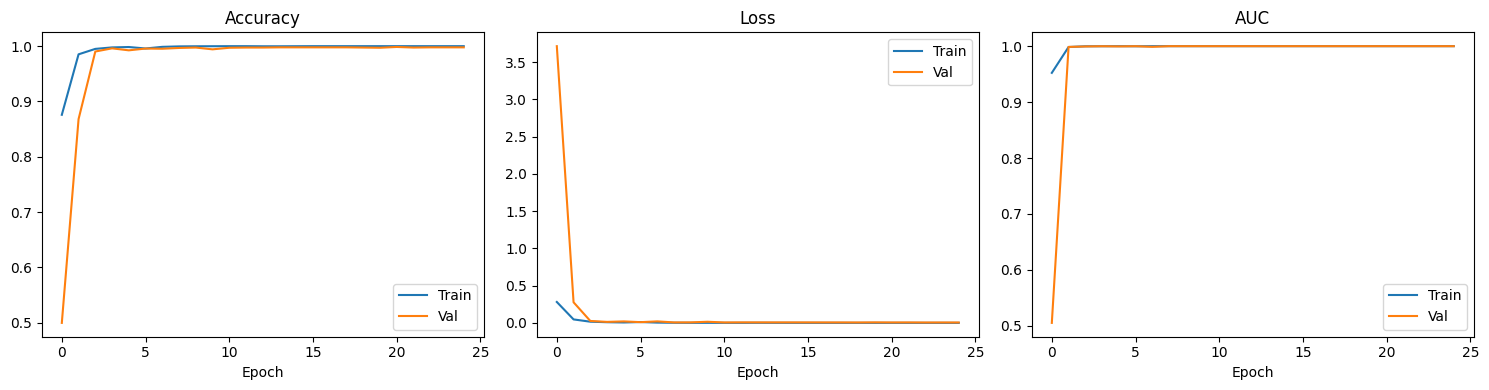

✅ Saved training_history.png to Google Drive


In [12]:
# CELL 11 — Plot training curves and save image
# Purpose: visualize train/val accuracy, loss, and AUC over epochs.

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(history.history.get('accuracy', []), label='Train')
axes[0].plot(history.history.get('val_accuracy', []), label='Val')
axes[0].set_title('Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history.history.get('loss', []), label='Train')
axes[1].plot(history.history.get('val_loss', []), label='Val')
axes[1].set_title('Loss')
axes[1].set_xlabel('Epoch')
axes[1].legend()

axes[2].plot(history.history.get('auc', []), label='Train')
axes[2].plot(history.history.get('val_auc', []), label='Val')
axes[2].set_title('AUC')
axes[2].set_xlabel('Epoch')
axes[2].legend()

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/training_history.png', dpi=150)
plt.show()
print("✅ Saved training_history.png to Google Drive")


In [13]:
# CELL 12 — Inference function using the exact preprocessing
# Purpose: run prediction on any uploaded audio file using the same preprocessing.

from tensorflow.keras.models import load_model

# Load model for inference (best checkpoint)
MODEL_FOR_INFER = BEST_PATH  # using the same best checkpoint

# Load once (re-use across multiple predicts)
_model_infer = load_model(MODEL_FOR_INFER)

def predict_file(file_path, threshold=0.5):
    """
    Run preprocessing -> model -> probability and label
    Returns (probability, label)
    """
    X_in = preprocess_audio_for_inference(file_path)
    prob = float(_model_infer.predict(X_in, batch_size=1).ravel()[0])
    label = "REAL" if prob >= threshold else "FAKE"
    print(f"File: {file_path}  |  Prediction: {label}  |  Confidence: {prob:.4f}")
    return prob, label

# Example usage after uploading a file to Colab:
# predict_file("/content/my_audio.wav")


In [22]:
# ============================================
# 🔥 TEST ANY AUDIO FILE FROM GOOGLE DRIVE
# (Updated for: MyDrive/original/real/filename.wav_2sec)
# ============================================

from tensorflow.keras.models import load_model

# Load the best model
MODEL_PATH = "/content/drive/MyDrive/best_model.h5"
model = load_model(MODEL_PATH)
print("✅ Model Loaded!")

def predict_from_drive(relative_path):
    """
    Pass only the path inside MyDrive, e.g.:

    'original/real/filename.wav_2sec'
    'original/fake/file123.wav_2sec'
    """

    # Build full absolute path inside Colab
    full_path = "/content/drive/MyDrive/" + relative_path

    print(f"\n🎧 Loading audio from Drive:\n{full_path}")

    # Preprocess using your exact training pipeline
    X = preprocess_audio_for_inference(full_path)

    # Predict
    prob = float(model.predict(X)[0][0])
    label = "REAL" if prob >= 0.5 else "FAKE"

    print("\n========== RESULT ==========")
    print(f"Prediction : {label}")
    print(f"Confidence : {prob:.4f}")
    print("================================\n")

    return prob, label

# ⭐ Example usage:
# predict_from_drive("original/real/filename.wav_2sec")
# predict_from_drive("original/fake/filename.wav_2sec")

✅ Model Loaded!


In [25]:
predict_from_drive("original/fake/file7.wav_16k.wav_norm.wav_mono.wav_silence.wav_2sec.wav")


🎧 Loading audio from Drive:
/content/drive/MyDrive/original/fake/file7.wav_16k.wav_norm.wav_mono.wav_silence.wav_2sec.wav
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step

========== RESULT ==========
Prediction : FAKE
Confidence : 0.0000



(4.586215851531961e-09, 'FAKE')